<div class="alert alert-block alert-success">
    
# Task 2 in Assessment 2
## **Student Team: 12**

#### **Students:**
##### [teammate], ID: [removed]
##### Akhmad Fauzi Nurulhamzah ID: [removed]


Date: 10/11/2025


Environment: Python 3.13.7

    
</div>

<div class="alert alert-block alert-danger">
    
## Table of Contents

</div>    

[1. Introduction](#1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[1.1. Objective](#1.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[1.2. Key Criteria for Reshaping](#1.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[1.3. Methodology Overview](#1.3) <br>

[2. Initial Data Loading and Cleaning](#2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.1. Import Libraries](#2.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.2. Mount Drive and Load Dataset](#2.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.3. Initial Inspection (Find Data Type Errors)](#2.3) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.4. Data Correction (Cleaning and Conversion))](#2.4) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.5. Verify Cleaning Result](#2.5) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[2.6. Check Missing data and duplicates](#2.6) <br>

[3. EDA to find anomalies](#2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[3.1. Outlier Analysis](#3.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[3.2. Different Scales Data (Quantitative Analysis)](#3.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[3.3. Non-Normal Distributions (Quantitative Analysis))](#3.3) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[3.4 Non-Linear Relationships (Visual Analysis))](#3.4) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[3.5. EDA Conclussion](#3.5) <br>

[4. Data Reshaping](#4) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[4.1. Data Transformation (Fixing Skew & Linearity)](#4.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.1.1. Transformation Functions](#4.1.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.1.2. Transformation Distributions](#4.1.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.1.3. Transformation Linearity Results](#4.1.3) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[4.2. Data Scaling (Fixing Scale))](#4.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.2.1. Scaling Functions](#4.2.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[4.2.2. Scaling Results (Quantitative)](#4.2.2) <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[3.2.3. Visualize Scaling Results](#4.2.3) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[4.3. Reshaping Conclusion](#4.3) <br>

[5. Quantitative Evaluation: Combining Methods](#5) <br>

[6. Conclusion and Recommendation](#6) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[6.1. Summary of Journey](#6.1) <br>
&nbsp;&nbsp;&nbsp;&nbsp;[6.2. Final Recommendation](#6.2) <br>

[7. References](#7) <br>

<div class="alert alert-block alert-warning">

## **1. Introduction** <a class="anchor" name="1"></a>
    
</div>

In this task, we will **conduct an exploratory data analysis** and data preparation process on the provided **suburb_info.xlsx** dataset. The primary goal is to investigate and prepare this data for a future linear regression model designed to predict the median_house_price.

Our analysis will focus on addressing the core assumptions of linear regression. This will involve two main investigations: first, comparing feature scaling techniques (like Standardization and Normalization) to bring all features onto a common scale, and second, applying transformations (like the log transform) to correct data skewness and improve the linear relationship between features and the target variable. This notebook will document our analysis and conclude with a final, evidence-based recommendation for the optimal data preparation pipeline.


### **1.1. Objective** <a class="anchor" name="1.1"></a>

The primary objective  is to perform a comprehensive exploratory data analysis and data preparation process on the *suburb_info.xlsx* dataset.

The ultimate goal is to investigate, identify, and remediate any data anomalies that violate the core assumptions of linear regression. This will ensure the dataset is fully prepared and suitable for building a valid, interpretable, and reliable model to predict **median_house_price**.

### **1.2. Key Criteria for Reshaping** <a class="anchor" name="1.2"></a>

To achieve the objective, our data preparation must satisfy the core assumptions of linear regression. We will focus on two key criteria which map directly to these assumptions:

1.   Remediate Skewed Data to Achieve Linearity: This criterion directly **addresses the assumptions of Normality, Linearity, and Homoscedasticity**. Regression models can be unreliable if the underlying data is heavily skewed, as this often leads to non-linear relationships or heteroscedasticity ("fanning"). Therefore, our process must first analyze the data's distributions and, if skew is present, apply and evaluate appropriate transformations.

2.   Ensure Features are on a Comparable Scale. This criterion **addresses the practical requirements for model interpretability and stability**. If features are on vastly different scales (exaample, a count in the thousands vs. a percentage), the resulting model coefficients will be misleading and cannot be directly compared to determine feature importance. Therefore, our process must also apply and evaluate scaling methods to create a stable and interpretable model.

### **1.3. Methodology Overview** <a class="anchor" name="1.3"></a>

This notebook will document our "journey" of exploration, as requested by the assignment. This process will follow a logical flow:

1.  Perform a **Complete Exploratory Data Analysis (EDA)** to load, clean, and analyze the "before" state of the data. This EDA is designed to find the "data anomalies" (skew, scale issues) that violate the two criteria.
2.  Introduce the **Data Reshaping Methodology**, where we clearly describe and justify our "suggested approach to fix those anomalies," explaining the reason for using each specific function.
3.  **Analyze the Transformed Data**, where the "effects of using different data-reshaping methods are shown in detail," using "all attributes" to visually and quantitatively prove the effects of our methods.
4.  Create Summary with a **Convincing Recommendation** for the optimal data preparation pipeline, based on the observations and evidence gathered.

<div class="alert alert-block alert-warning">

## **2. Initial Data Loading and Cleaning** <a class="anchor" name="2"></a>
    
</div>

Before analysis, we will load the data, clean it, and then perform a **complete EDA** to establish the "before" state and identify any "anomalies" that violate our model's assumptions.

In [22]:
#@title 2.1 Import Libraries

#Core libraries for data manipulation and math
import pandas as pd
import numpy as np
import sys

#Libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Libraries for preprocessing and modeling
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, PowerTransformer
from sklearn.linear_model import LinearRegression
from scipy.stats import boxcox
import warnings

#Set a consistent style for plots
sns.set(style="whitegrid")
# Suppress warnings for cleaner output (e.g., from PowerTransformer)
warnings.filterwarnings('ignore')

The packages to be used in this assessment are imported in the following. They are used to fulfill the following tasks:

* **pandas**: to handle, clean, and analyze tabular data using DataFrame structures, including reading data from files, transforming columns, and performing aggregations.
* **numpy**: perform fast numerical and mathematical operations
* **matplotlib.pyplot**: to create data visualizations for exploratory data analysis.
* **seaborn**: to produce aesthetically appealing and statistically informative plots built on top of matplotlib, simplifying the creation of complex visualizations like boxplots, heatmaps, and distribution plots.
* **sys:** to interact with the Python runtime environment, such as reading command-line arguments or managing system paths.
* **sklearn.preprocessing**: to perform feature scaling and transformation before modeling, using techniques such as StandardScaler for standardization, MinMaxScaler for normalization, and PowerTransformer for normalizing skewed data distributions.
* **sklearn.linear_model**: to implement linear regression for modeling relationships between independent and dependent variables and making predictions based on continuous outcomes.
* **scipy.stats**: to perform statistical operations and transformations, including the Box-Cox transformation, which stabilizes variance and helps data conform to normal distribution assumptions.
* **warnings**: to manage or suppress warning messages generated during program execution, ensuring cleaner outputs during data preprocessing or model training.


In [23]:
#@title 2.2 Mount the Drive and Load Dataset


#Mount drive (run once)
from google.colab import drive
drive.mount('/content/drive')

#load data
base_path = "/content/drive/MyDrive/ITI5196_DW/A2_dataset/"
suburb_file = "suburb_info.xlsx"

print(f"Loading file: {base_path + suburb_file}")

#Load the excel file
df = pd.read_excel(base_path + suburb_file)

print("\nSuccessfully loaded suburb_info.xlsx:")
print(f"data shape: {df.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading file: /content/drive/MyDrive/ITI5196_DW/A2_dataset/suburb_info.xlsx

Successfully loaded suburb_info.xlsx:
data shape: (202, 8)


**This** step is to mount  Google Drive to the Colab environment using the google.colab library. This process will allows to access datasets and save output files directly to my Drive, ensuring data persistence across sessions. By executing drive.mount('/content/drive'), Drive storage became accessible under the /content/drive directory, enabling seamless integration between Google Drive and the Colab workspace.

Then we load the suburb_info.xlsx data from the gdrive, and with df.shape we can know that the dataset have **202 rows, and 8 column** which we will inspect more in the future

In [24]:
#@title 2.3 Initial Inspection (Find Data Type Errors)

#review metadata
df.info()

#View dataset
df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   suburb              202 non-null    object
 1   number_of_houses    202 non-null    int64 
 2   number_of_units     202 non-null    int64 
 3   municipality        202 non-null    object
 4   aus_born_perc       202 non-null    object
 5   median_income       202 non-null    object
 6   median_house_price  202 non-null    object
 7   population          202 non-null    int64 
dtypes: int64(3), object(5)
memory usage: 12.8+ KB


,suburb,number_of_houses,number_of_units,municipality,aus_born_perc,median_income,median_house_price,population
0,ABBOTSFORD,2304,4706,Yarra,68%,"$1,797","$1,299,400",4025
1,ABERFELDIE,1410,453,Moonee Valley,81%,"$1,571","$1,926,600",22442
2,ALBANVALE,1897,138,Brimbank,46%,$907,"$594,200",54005
3,ALBION,1389,1392,Brimbank,52%,$929,"$739,100",30677
4,ALPHINGTON,1729,1099,Darebin,73%,"$1,538","$1,729,600",9227


**Observation Insight**


The dataset contains 202 rows (entries) with **no null** values, each representing one record, and 8 columns. Below is an explanation of each column based on the summary:

*  **suburb** = The suburb name, which serves as the index of the data
*  **number_of_houses** = The number of houses in the property suburb
*  **number_of_units** = The number of units in the property suburb
*  **municipality** = The municipality of the property suburb
*  **aus_born_perc** = The percentage of the Australian-born population in the property suburb
*  **median_income** = The median income of the population in the property suburb
*  **median_house_price** = The median 'house' price in the property suburb population The population in the property suburb



**Spotted Issue**

our initial *.info()* analysis revealed a critical data type problem. The  analysis of **median_house_price, median_income, and aus_born_perc** were all incorrectly loaded as object **(text)** data types.


In [25]:
#Inspecting the 'object' Columns

#check median_house_price
print("Inspecting 'median_house_price' (first 10 rows)")
print(df['median_house_price'].head(10))

#check median_income
print("\n Inspecting 'median_income' (first 10 rows)" )
print(df['median_income'].head(10))

#check aus_born_perc
print("\n  Inspecting 'aus_born_perc' (first 10 rows)")
print(df['aus_born_perc'].head(10))

Inspecting 'median_house_price' (first 10 rows)
0    $1,299,400
1    $1,926,600
2      $594,200
3      $739,100
4    $1,729,600
5    $1,139,500
6      $935,500
7      $663,400
8    $1,925,900
9    $1,436,500
Name: median_house_price, dtype: object

 Inspecting 'median_income' (first 10 rows)
0    $1,797
1    $1,571
2      $907
3      $929
4    $1,538
5    $1,160
6      $910
7      $895
8    $1,713
9    $1,469
Name: median_income, dtype: object

  Inspecting 'aus_born_perc' (first 10 rows)
0    68%
1    81%
2    46%
3    52%
4    73%
5    70%
6    52%
7    46%
8    73%
9    73%
Name: aus_born_perc, dtype: object


**Observation Insight**


Object is the pandas term for a column that holds mixed types, it usually strings (text) and rom visual inspection of the **.head()** output it confirmed that in the dataset:


*   median_house_price contains `$` and , characters for example `"$1,299,400"`
*   median_income also contains $ and , characters for example `"$1,797"`
*   aus_born_perc contains % characters for example: `"73%"`


These non-numeric characters force pandas to treat the entire column as text, and this is a critical data anomaly because we cannot perform any mathematical operations (like calculating a mean, skew, or running a regression) on text.

Because of this, in the next step we will fix it using string replacement (.str.replace()) to remove these characters and then convert the columns to a proper numeric type (like int or float) using pd.to_numeric()

In [26]:
#@title 2.4 Data Correction (Cleaning and Conversion)

#remove '$' and ',' and whitespace from 'median_house_price'
df['median_house_price'] = df['median_house_price'].str.replace(r'[$,\s]', '', regex=True)

#remove '$' and ',' from 'median_income'.
df['median_income'] = df['median_income'].str.replace(r'[$,]', '', regex=True)

#remove the '%' from 'aus_born_perc'.
df['aus_born_perc'] = df['aus_born_perc'].str.replace('%', '')

#convert the cleaned strings to numbers.
df['median_house_price'] = pd.to_numeric(df['median_house_price'], errors='coerce')
df['median_income'] = pd.to_numeric(df['median_income'], errors='coerce')
df['aus_born_perc'] = pd.to_numeric(df['aus_born_perc'], errors='coerce')

#convert price and income to 'int' for cleaner data
df['median_house_price'] = df['median_house_price'].astype(int)
df['median_income'] = df['median_income'].astype(int)

**Justification:**
*   We use regex = True to efficiently find and remove all dollar sign ($), comas (,), or whitespace in the 'median_house_price', 'median_income' and aus_born_perc column
*   We use pd.to_numeric to convert the cleaned strings to numbers.the use of 'errors=coerce' is a safety setting that will turn any remaining bad data into 'NaN' (Not a Number) in case we find any
*   We also convert price and income to 'int' for cleaner data, because they represent whole dollar amounts for easy analysis in the future.


In [27]:
#@title 2.5 Verify cleaning result

#metadata
df.info()

#data view
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202 entries, 0 to 201
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   suburb              202 non-null    object
 1   number_of_houses    202 non-null    int64 
 2   number_of_units     202 non-null    int64 
 3   municipality        202 non-null    object
 4   aus_born_perc       202 non-null    int64 
 5   median_income       202 non-null    int64 
 6   median_house_price  202 non-null    int64 
 7   population          202 non-null    int64 
dtypes: int64(6), object(2)
memory usage: 12.8+ KB


,suburb,number_of_houses,number_of_units,municipality,aus_born_perc,median_income,median_house_price,population
0,ABBOTSFORD,2304,4706,Yarra,68,1797,1299400,4025
1,ABERFELDIE,1410,453,Moonee Valley,81,1571,1926600,22442
2,ALBANVALE,1897,138,Brimbank,46,907,594200,54005
3,ALBION,1389,1392,Brimbank,52,929,739100,30677
4,ALPHINGTON,1729,1099,Darebin,73,1538,1729600,9227


**Observation insight**

After the data cleaning and conversion, the updated data types for our df (suburb info) are as follows:


*  **suburb and municipality**: remain as object because they contain non-numeric text data used for identification.

*   **number_of_houses, number_of_units, and population**: remain in their original numeric format (int64) as they were loaded correctly.

*   **median_house_price, median_income, and aus_born_perc**: now have the correct numeric format (converted to int64 and float64).

As we can see that the variable that were previously object (text) types due to non-numeric characters like dollar sign ($), comas (,), and percent (%) has changed to integer. with this change, now we are enables all necessary mathematical and statistical operations for our analysis.

In [28]:
#@title 2.6 Check Missing Data and Duplicates

#Check null values
print("Missing Value Count")
print(df.isna().sum())

#Check duplicated rows
print("\n Duplicate Row Count")
print(df.duplicated().sum())

Missing Value Count
suburb                0
number_of_houses      0
number_of_units       0
municipality          0
aus_born_perc         0
median_income         0
median_house_price    0
population            0
dtype: int64

 Duplicate Row Count
0


As we see from the metadata (df.info) we validate this with isna and we **do not have null value**, we also** do not have duplicated** data/row in the dataset

The final dataset contains **202 observations (rows) and 8 variables (columns)**. Each row represents a suburb in Melbourne, and each column provides information describing that suburb.

The dataset now has no missing values, **all data type were correct,** where numeric variables have the correct integer data type, and text-based variables are properly recognized as object types.

Each column is represent:
*  **suburb** = The suburb name, which serves as the index of the data
*  **number_of_houses** = The number of houses in the property suburb
*  **number_of_units** = The number of units in the property suburb
*  **municipality** = The municipality of the property suburb
*  **aus_born_perc** = The percentage of the Australian-born population in the property suburb
*  **median_income** = The median income of the population in the property suburb
*  **median_house_price** = The median 'house' price in the property suburb population The population in the property suburb

## **3. EDA to find anomalies** <a class="anchor" name="3"></a>

Now we perform our **EDA** to check if the two assignment criteria are met (Criterion 1: Features must be on the same scale and Criterion 2: Features must have a strong linear relationship with the target variable)

This EDA is designed to find the "data anomalies" (skew, scale issues) that violate the assumptions of linear regression.

We will analyze these 5 features and 1 target variable:
* **Features (X):** number_of_houses, number_of_units, population, aus_born_perc, median_income
* **Target (y):** median_house_price

Analyzing the distribution of all numerical features for outliers...


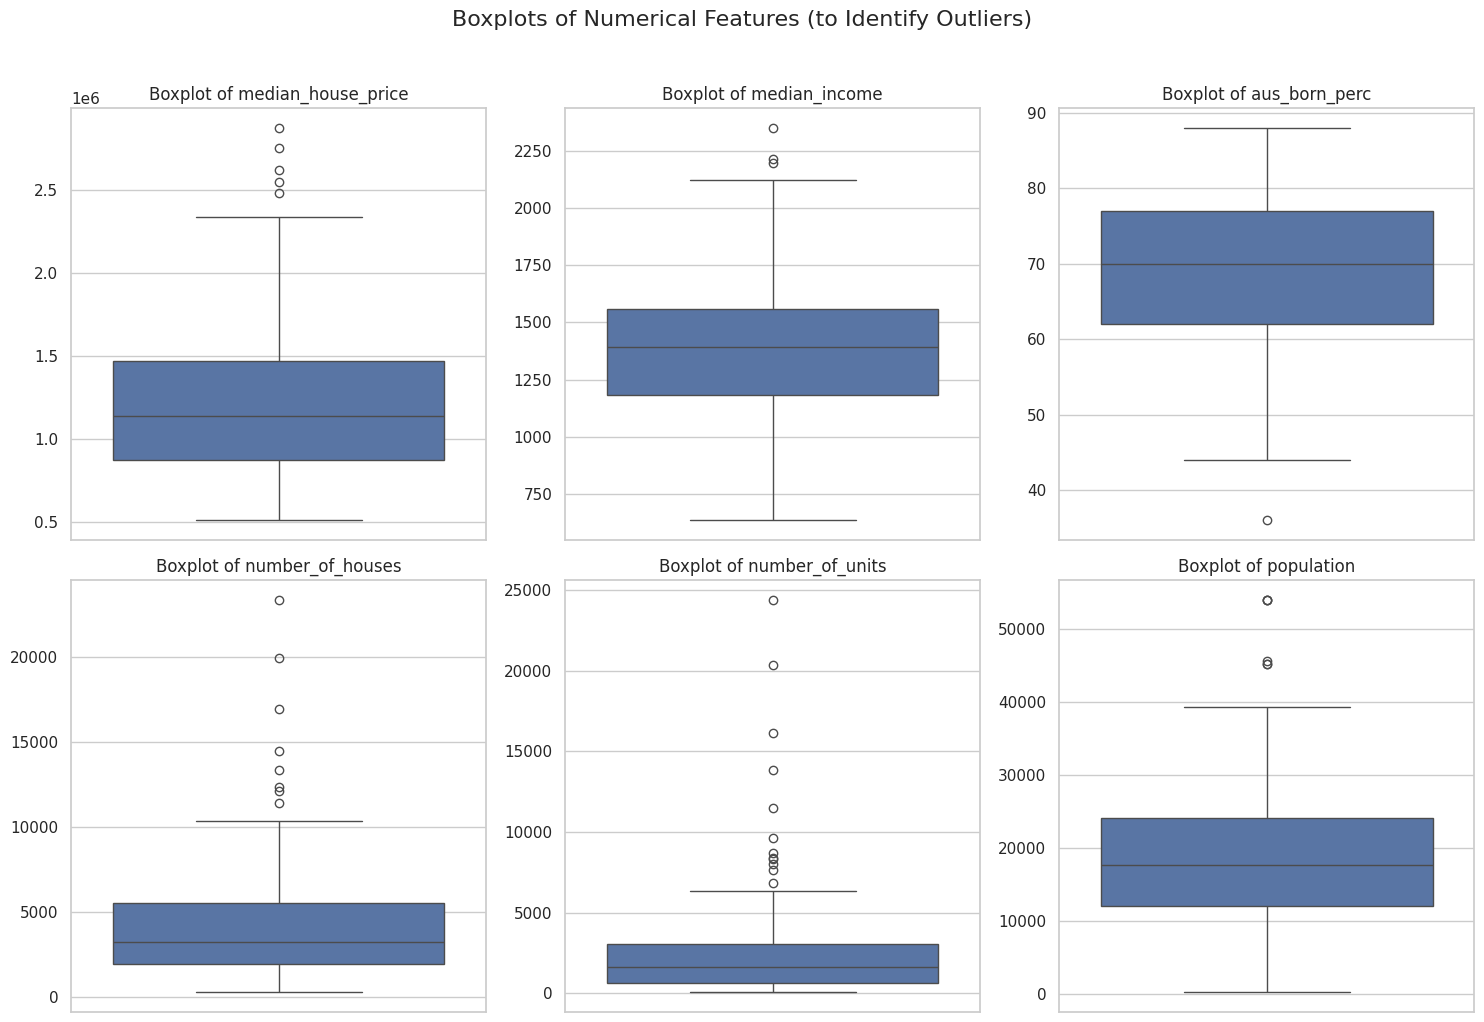

In [29]:
#@title 3.1 Outlier Analysis
print("Analyzing the distribution of all numerical features for outliers...")


numerical_features = [
    'median_house_price', 'median_income', 'aus_born_perc',
    'number_of_houses', 'number_of_units', 'population'
]
features = ['number_of_houses', 'number_of_units', 'population', 'aus_born_perc', 'median_income']
target = 'median_house_price'


# Set up a figure with 6 subplots
plt.figure(figsize=(15, 10))

# Loop through our list of features and create one boxplot for each
for i, feature in enumerate(numerical_features):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[feature])
    plt.title(f'Boxplot of {feature}', fontsize=12)
    plt.ylabel('') # Hide the y-axis label to keep it clean

plt.suptitle('Boxplots of Numerical Features (to Identify Outliers)', y=1.02, fontsize=16)
plt.tight_layout() # Prevents plots from overlapping
plt.show()

In [30]:
# Quantitative Outlier Analysis (1.5 * IQR Rule)

outlier_summary = [] # To hold the data for creating the table

#Loop through each feature to calculate its outlier stats
for feature in numerical_features:
    # Calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    #Calculate the Interquartile Range (IQR)
    IQR = Q3 - Q1

    #Define the outlier bounderies/fences
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR

    #Count the number of outliers
    total_outliers = df[(df[feature] < lower_fence) | (df[feature] > upper_fence)].shape[0]

    #Calculate what percentage of the data are outliers
    total_rows = df.shape[0]
    perc_outliers = (total_outliers / total_rows) * 100

    # Store the results for our table
    outlier_summary.append({
        'Feature': feature,
        'Total Outliers': total_outliers,
        '% Outliers': f"{perc_outliers:.2f}%"
    })

#Create and Display the Summary Table
outlier_table = pd.DataFrame(outlier_summary).set_index('Feature')
print("\n Outlier Count Summary (1.5 * IQR Rule)")
print(outlier_table.to_string(float_format="%.0f"))


 Outlier Count Summary (1.5 * IQR Rule)
                    Total Outliers % Outliers
Feature                                      
median_house_price               5      2.48%
median_income                    3      1.49%
aus_born_perc                    1      0.50%
number_of_houses                 8      3.96%
number_of_units                 12      5.94%
population                       6      2.97%


**Insight & Justification (from Boxplots and IQR Table):**

The boxplots confirm that outliers are present in **median_house_price**, **median_income, aus_born_perc, number_of_houses, number_of_units, and population**.

The compressed box and long upper whisker are classic signs of a strong right-skew. (as we will confirm in 3.3 using histogram). The data indicate that few suburbs having much larger values than the rest. For example, while most suburbs have relatively small populations and housing counts, a few contain significantly more housing units or residents. this is why these extreme values appear as outliers in boxplots.

**The IQR Table quantifies that the dataset has 23 outliers**, with number_of_unit has the highest number of outlier which is 5.9% of thevariable data. This is quite high number and confirms the visual skew.

However, these outliers were not removed because they are **genuine data points**, not data entry errors. They represent real, larger suburbs with higher housing density or population size. Removing them would risk to reduce the representativeness of the dataset and may create distortion to the relationship between predictors and the target variable (median_house_price), especially since high-income or densely populated suburbs are often the ones driving price differences, making the model less accurate for diverse suburb types.

Then, Instead of deleting them, we will apply data transformation to reduce their influence. This transformation will help compresses large values and spreads smaller ones more evenly, producing more normally distributed features while keeping all valid information intact


#### **3.2. Different Scales Data (Quantitative Analysis)** <a class="anchor" name="3.2"></a>
We check if features are on the same scale by using `.describe()`.

In [31]:
#Scale Checking (Criterion 1)

print("\n Descriptive Statistics (Checking for Scale)")
df.describe()


 Descriptive Statistics (Checking for Scale)


,number_of_houses,number_of_units,aus_born_perc,median_income,median_house_price,population
count,202.000000,202.000000,202.000000,202.000000,2.020000e+02,202.000000
mean,4155.767327,2480.410891,68.366337,1387.935644,1.218817e+06,18659.311881
std,3400.864988,3132.684712,10.761293,317.841321,4.716807e+05,9604.187282
min,283.000000,60.000000,36.000000,633.000000,5.072000e+05,170.000000
25%,1973.500000,620.500000,62.000000,1182.250000,8.706750e+05,12063.000000
50%,3256.500000,1603.000000,70.000000,1393.000000,1.134500e+06,17583.000000
75%,5518.500000,3089.000000,77.000000,1560.000000,1.467550e+06,24045.000000
max,23338.000000,24380.000000,88.000000,2352.000000,2.875800e+06,54005.000000


**Insight & Justification (from `.describe()` Table):**


The **.describe()** table provides a clear numerical comparison of our features. This table reveals that the **magnitudes of the features are wildly different**.

for example when comparing population and aus_born_perc mean and max values:
* **`population`**: mean = **18,659** | max = **54,005**
* **`aus_born_perc`**: mean = **68.3** | max = **88**

This is an **anomaly** because A linear regression model works by finding a "weight" (or coefficient) for each feature. If **population's** numbers are hundreds of times larger than **aus_born_perc's**, the model's algorithm (which is based on minimizing error) will get confused.

It will **incorrectly assume `population` is thousands of times more important** than aus_born_perc simply because its numbers are bigger, even if aus_born_perc is actually a better predictor. This can cause the model to be unstable and produce unreliable results.

and this is the reason why **Scaling is absolutely necessary**. We must apply a scaling function (like StandardScaler, MinMaxScaler or apply other scalling method) to put all features on a common range (e.g., all between 0 and 1, or all with a mean of 0). This allows the model to fairly compare their predictive power.

#### **3.3. Non-Normal Distributions (Quantitative Analysis)** <a class="anchor" name="3.3"></a>
We check for skewness in the numerical features using histograms. with this we can see and determine which variables need to transform which not

Analyzing the distribution of all *original* numerical features...


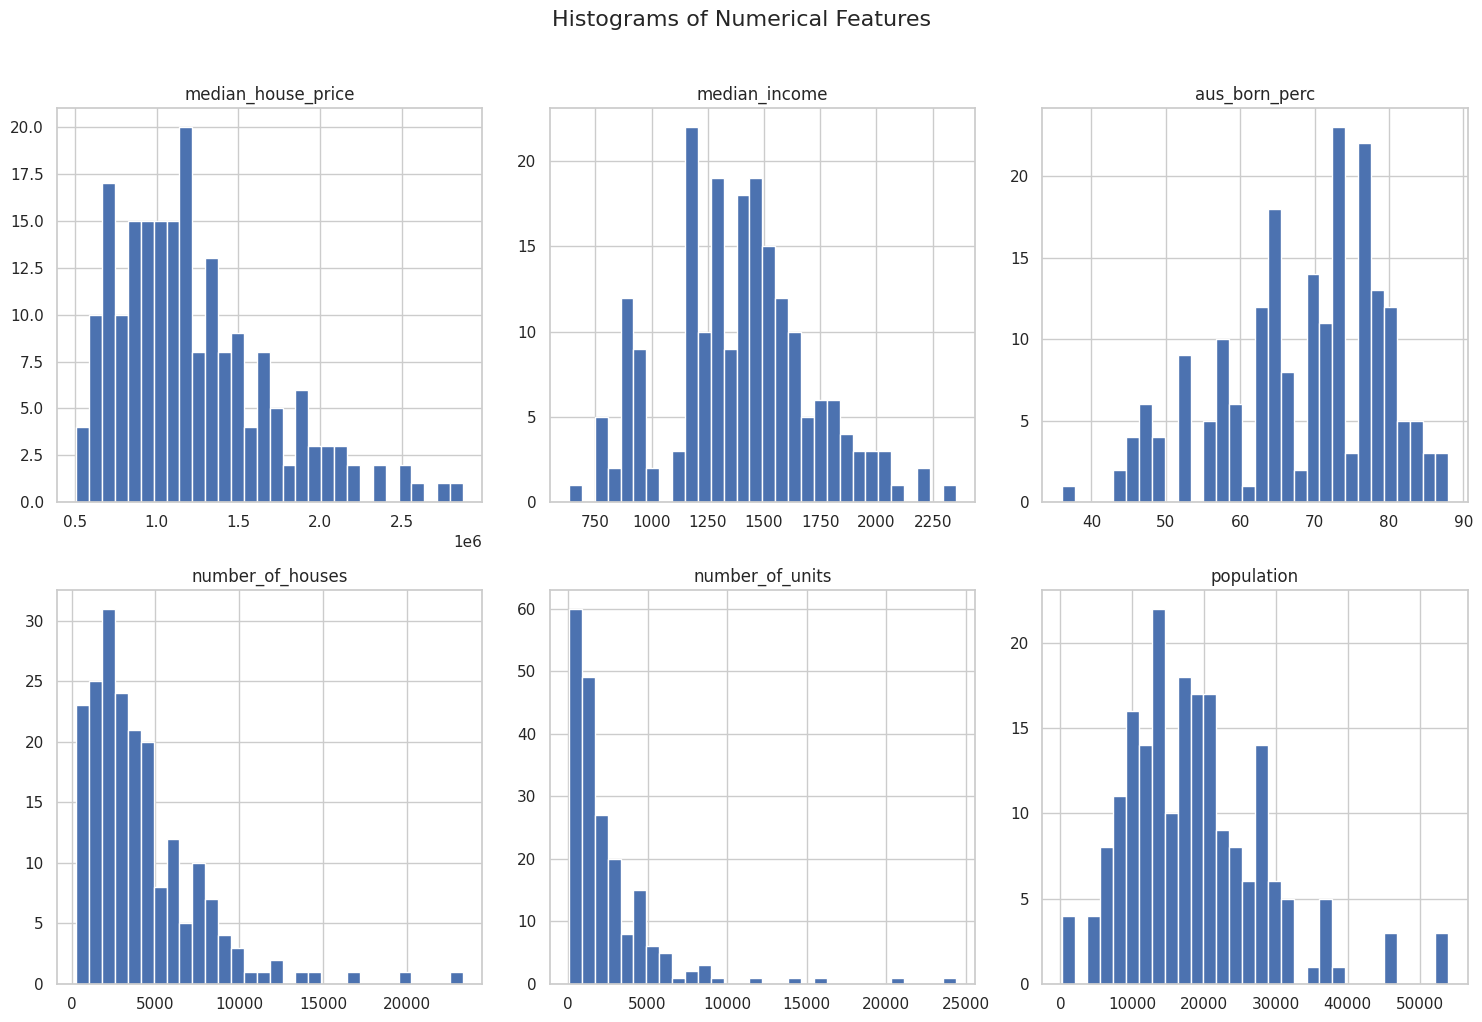


Skewness Values for Features
A value > 1.0 or < -1.0 is generally considered 'highly skewed'.
median_house_price    1.033261
median_income         0.172518
aus_born_perc        -0.567896
number_of_houses      2.156185
number_of_units       3.630165
population            1.085865
dtype: float64


In [32]:
#Checking Distribution (Criterion 2)
print("Analyzing the distribution of all *original* numerical features...")

# Create the histograms
df[numerical_features].hist(
    bins=30,          # Number of bars in each histogram
    figsize=(15, 10), # Total size of the figure (width, height in inches)
    layout=(2, 3)     # Arrange the plots in a 2x3 grid
)

plt.suptitle('Histograms of Numerical Features', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

#Print Skewness Values for Features
print("\nSkewness Values for Features")
print("A value > 1.0 or < -1.0 is generally considered 'highly skewed'.")
print(df[numerical_features].skew())

**Insight & Justification (from Histograms and Skew Values):**


*   **median_house_price** histogram shows a concentration of values between approximately 0.6 million dollar and 1.5 million dollar, with a long right tail extending toward $2.8 million. The positive **skewness value (1.03**) confirms that this variable is **right-skewed**, meaning most suburbs have moderate house prices, while a few high-priced suburbs pull the distribution upward.

*   **median_income** variable has a **skewness value of 0.17**, which is very close to zero. Its histogram looks **roughly symmetric and centered around 1**,200-1,500, indicating that income levels are fairly evenly distributed across suburbs with no strong skew. This variable does not require transformation.

*   **aus_born_perc** variable has a mild n**egative skewness (-0.57)**. Its histogram shows that most suburbs have a high percentage of Australian-born residents (around 65%-80%), while only a few suburbs have lower percentages. This slight left skew is not severe enough to distort analysis and does not require transformation.

*   **number_of_houses** and **number_of_units** variables are both **strongly right-skewed, with skewness values of 2.16 and 3.63**, respectively. Their histograms confirm this: both have a large concentration of small values near the lower end and a few extremely large values on the right. This pattern suggests that most suburbs have a moderate number of houses or units, while a small number of large, high-density suburbs dominate the upper tail. Because these variables have skewness greater than 1.0, they require transformation (such as Yeo-Johnson or logarithmic) to achieve more normal distributions.

*  **population** hist displays a noticeable right skew (1.09). The histogram shows that most suburbs have populations between 10,000 and 25,000, but a few very large suburbs have over 50,000 residents. This moderate positive skew indicates that transformation would help stabilize variance and make relationships with other variables, such as house price, more linear.


In summary, many features are highly skewed with the skewness value > 1.0, in **number_of_houses (skew=2.16)**, **number_of_units (skew=3.63)**, **population (skew=1.09)**, **median_house_price (skew=1.03)** and this need to transform

**median_income (0.17) and aus_born_perc (-0.57)** are relatively symmetrical and will not require transformation.

**Transformation will be necessary** for the highly skewed features to make their distributions more symmetrical.


#### **3.4 Non-Linear Relationships (Visual Analysis)** <a class="anchor" name="3.4"></a>
We check for linear relationships directly by plotting each feature against the target variable, `median_house_price`.

Analyzing relationships between numerical features and the target variable (median_house_price)


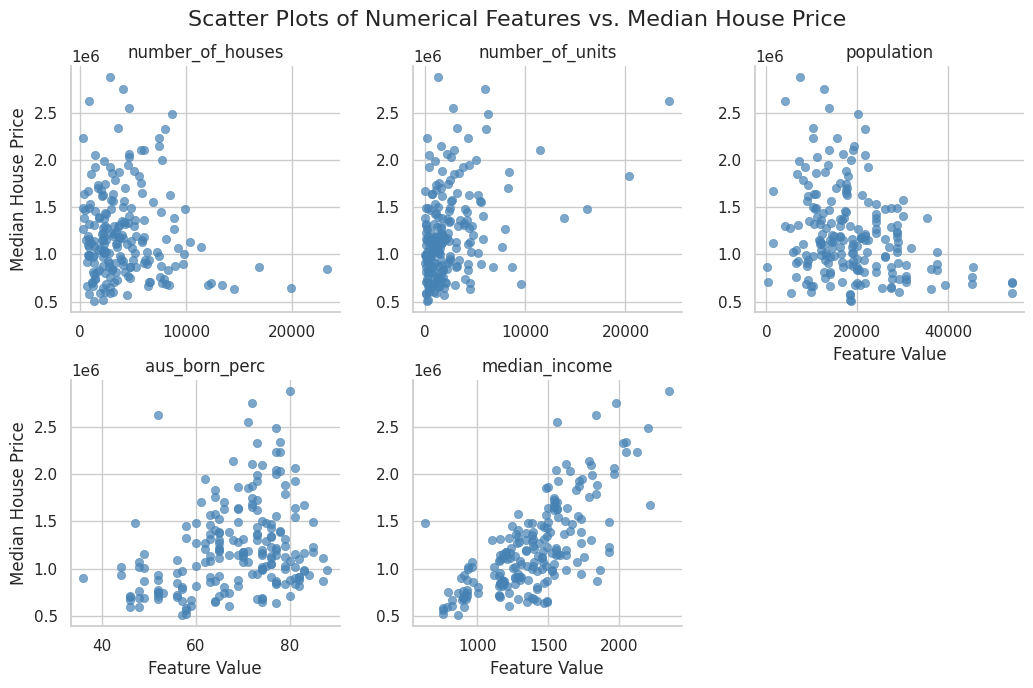


--- Pearson Correlations with Target ---
median_house_price    1.000000
median_income         0.719384
number_of_units       0.343858
aus_born_perc         0.303860
number_of_houses     -0.104490
population           -0.287242
Name: median_house_price, dtype: float64


In [33]:
#Scatter Plots (Linearity Check)
print("Analyzing relationships between numerical features and the target variable (median_house_price)")

# Create a tidy (melted) version of the data for Seaborn FacetGrid plotting
df_melted = df.melt(id_vars=target, value_vars=features, var_name='Feature', value_name='Value')

# Create a facet grid of scatter plots using Seaborn
g = sns.FacetGrid(df_melted, col='Feature', col_wrap=3, height=3.5, sharex=False, sharey=False)
g.map_dataframe(sns.scatterplot, x='Value', y=target, alpha=0.7, color='steelblue', edgecolor=None)

g.set_titles(col_template="{col_name}")
g.set_axis_labels("Feature Value", "Median House Price")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Scatter Plots of Numerical Features vs. Median House Price", fontsize=16)
plt.show()

# Print correlation coefficients
print("\n--- Pearson Correlations with Target ---")
corr = df[features + [target]].corr()[target].sort_values(ascending=False)
print(corr)

In general, the data shows that **median income** has the strongest and most consistent positive relationship with **median house price**, making it a key predictor for housing values. Meanwhile, **number of units and aus_born_perc** also have weak to moderate positive correlations, suggesting that areas with more housing units and higher proportions of Australian-born residents tend to have slightly higher house prices. In contrast, **population and number_of_houses** show mild negative relationships, indicating that larger or denser areas may experience lower median house prices, possibly due to higher housing supply or lower average income levels.

A **potential problem **for building a linear regression model with this data is that **many features show nonlinear relationships and heteroscedasticity (the spread of data points is uneven)**. Some variables, such as population and number_of_houses, have extreme outliers and heavily skewed distributions. These issues violate the assumptions of linear regression, which requires a linear relationship and normally distributed residuals.

To fix this problem, we will apply data transformations such as log transformation, square root transformation, or Yeo-Johnson/Box-Cox transformations to make the distributions more symmetric and reduce the influence of outliers. Additionally, applying normalization or scaling (like StandardScaler or MinMaxScaler) can help balance feature magnitudes, making the model more stable and accurate. Outliers can also be capped or removed if they distort the regression line too much. These preprocessing steps would make the data more suitable for linear modeling.

### **3.5. EDA Conclusion** <a class="anchor" name="3.5"></a>

Our **complete EDA** confirms that the raw, cleaned data is **not suitable** for linear regression. We have found two major categories of "anomalies" that violate the assignment's criteria:

1.  **Different Scales (Criterion 1 Violation)**
    * **Finding:** Features are on vastly different scales (e.g., `population` mean ~ 18k vs. `aus_born_perc` mean ~ 68).
    * **Suggested Fix:** **Scaling is required.**

2.  **Skew & Non-Linearity (Criterion 2 Violation)**
    * **Finding:** Key features (and the target) are highly right-skewed (e.g., `number_of_units` skew = 3.63). This causes non-linear "fanned-out" relationships.
    * **Suggested Fix:** **Transformation is required.**

Our methodology will be to **first apply transformations** to fix skew and linearity (Criterion 2), and **then apply scaling** to fix the scales (Criterion 1).

<div class="alert alert-block alert-warning">

## **4. Data Reshaping** <a class="anchor" name="4"></a>
    
</div>

Based on our EDA, we must reshape the data. In this section we will explains the "suggested approach" and "justifies the reason for using" each function

### **4.1 Data Transformation (Fixing Skew & Linearity)** <a class="anchor" name="4.1"></a>

To fix the heavy right-skew and non-linear "fanning" we found in Section 2, we must apply a power transformation. These functions compress the long tail of high values and spread out the bunched-up low values, making the data more symmetrical. We will analyze the four most common methods.


1.  **Square Root Transformation (`np.sqrt`)**: A simple method for reducing moderate right-skew. It's less aggressive than a log transform. By taking the square root, it "pulls in" the large values more than the small values, compressing the long tail. We will clip data at 0 to avoid errors with any potential negative numbers.

2.  **Log Transformation (`np.log1p`)**: A powerful and common method for heavy right-skew. log1p is used (calculating log(x+1)) to handle any potential 0 values. This often turns a curved, "fanned-out" relationship into a more linear one. We use log1p (which calculates log(x+1)) to avoid errors if any data points are 0.

3.  **Box-Cox Transformation (`scipy.stats.boxcox`)**: An automated method that finds the *best* power $\lambda$ to apply to make the data "normal." It has a critical limitation: it **only works on data that is strictly positive** (> 0).

4.  **Yeo-Johnson Transformation (`PowerTransformer(method='yeo-johnson')`)**: A more robust version of Box-Cox. It also finds the best power $\lambda$, but it **works on data with zeros and negative numbers**.

**Justification for Selected Transformation Methods**

The transformation methods tested (log1p, sqrt, boxcox, and yeo-johnson) were selected to provide a comprehensive comparison of the two primary approaches for correcting right-skewed data:


*   **Classic, Fixed Transformations (log1p, sqrt)**: These are the most common, traditional, and interpretable methods for normalizing skewed distributions. The log1p (log(x+1)) function is specifically chosen over the standard log(x) because it is mathematically stable and can handle zero values, which we identified as being present in features like number_of_units. The sqrt (square root) transformation is included as a common, "milder" alternative.
*   **Adaptive Power Transformations (boxcox, yeo-johnson):** These are more modern, flexible, and powerful methods. Instead of applying a single fixed function, these PowerTransformer algorithms mathematically find the optimal lambda (λ) parameter that makes the data distribution as symmetrical (Gaussian-like) as possible. We test both:
    -   Box-Cox: A highly effective method, but with the strict limitation that it only works on data that is strictly positive (greater than zero).
    -   Yeo-Johnson: This is the most robust and flexible method available. It is an extension of Box-Cox that is mathematically valid for data containing zero or negative values.

By testing these two distinct categories, we can evaluate whether a simple, classic transformation is sufficient for this dataset, or if a more complex, adaptive "power transform" provides a measurably superior result. The quantitative evaluation in Section 4 will provide the definitive, evidence-based answer.

**Transformed Variables**

Based on our findings in the Exploratory Data Analysis (Section 2.2.3), we identified two distinct groups of features:


*   Skewed Features:**number_of_units (skew: 3.63), number_of_houses (skew: 2.16), and population (skew: 1.09)** were all found to be highly right-skewed.

*   Symmetrical Features: **median_income (skew: 0.35) and aus_born_perc (skew: -0.37)** were found to be already normally distributed.

Therefore, in the following R-Squared evaluation, any pipeline that includes a transformation step will **only apply that transformation to the highly skewed features** (number_of_units, number_of_houses, population).

The two symmetrical features (median_income, aus_born_perc) will remain in their original,untransformed state throughout all tests. This ensures we are only "fixing" the data that is "broken" and preserving the data that already meets the model's assumptions.

In [34]:
#@title 4.1.1 Transformation Functions

#We define these functions here to apply all 4 transformations (box-cox, log, square root, yeo-johnson)

def try_boxcox(x):

    #Safely apply Box-Cox transformation (only for strictly positive values). and returns None if data contains 0 or negative values
    if x.dropna().le(0).any(): # Fails if any value is <= 0
        return None
    if x.dropna().nunique() < 2: # Not enough unique values
        return None
    # Apply boxcox
    vt, lmbda = boxcox(x.dropna())
    # Create a new series to hold the transformed data
    res = pd.Series(index=x.index, dtype=float)
    res.loc[x.dropna().index] = vt
    return res

def apply_transform(series, method):

    #Apply different transformation methods to a Pandas Series. This function contains the logic for each transformation.

    s = series.copy().astype(float)

    #1.No transformation
    if method == 'none':
        return s

    #2.Log Transformation
    elif method == 'log1p':
        # Use log1p (log(x+1)) to handle potential zero values
        return np.log1p(s.clip(lower=0))

    #3.Square Root Transformation
    elif method == 'sqrt':
        return np.sqrt(s.clip(lower=0))

    #4.Yeo-Johnson Transformation
    elif method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson', standardize=False)
        arr = s.values.reshape(-1,1)
        # Fill NaNs with median for transformation fitting, if any
        arr_filled = np.where(np.isnan(arr), np.nanmedian(arr), arr)
        transformed = pt.fit_transform(arr_filled)
        return pd.Series(transformed.ravel(), index=s.index)

    #5. Box-Cox Transformation
    elif method == 'boxcox_when_possible':
        transformed = try_boxcox(s)
        # Return original data if boxcox fails (e.g., due to zeros)
        return transformed if transformed is not None else s
    else:
        return s


 Skewness before transformation:
number_of_houses      2.156185
number_of_units       3.630165
population            1.085865
median_house_price    1.033261
dtype: float64


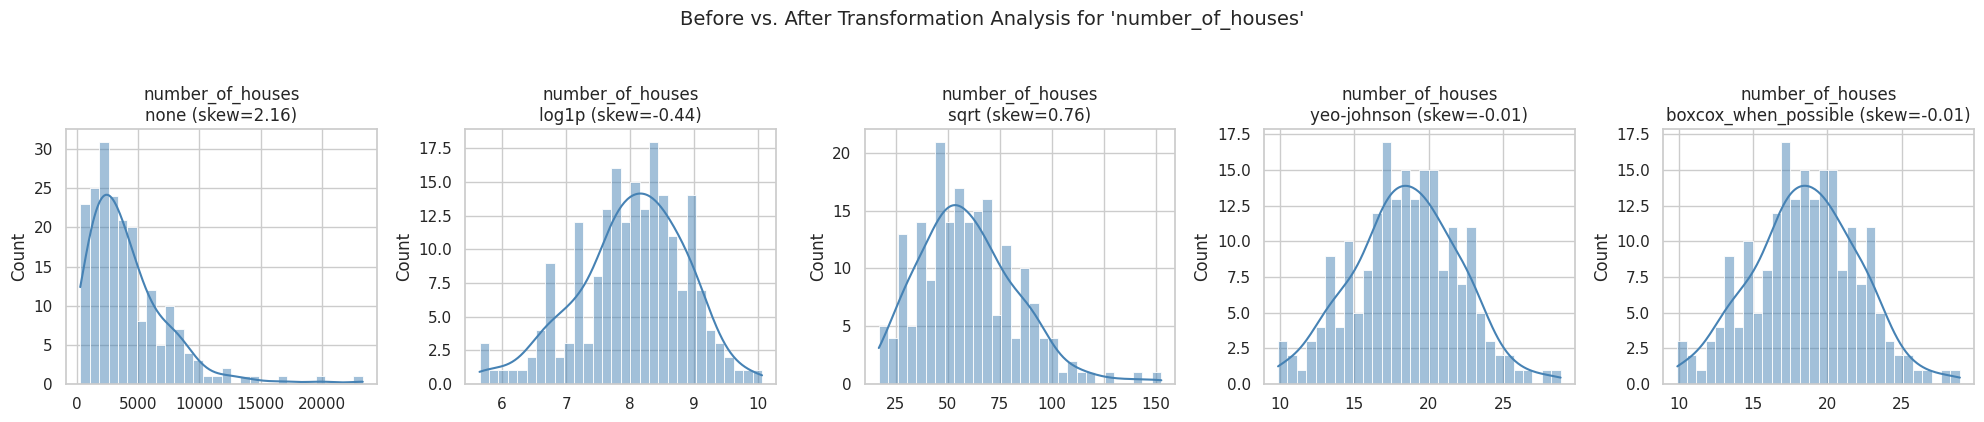

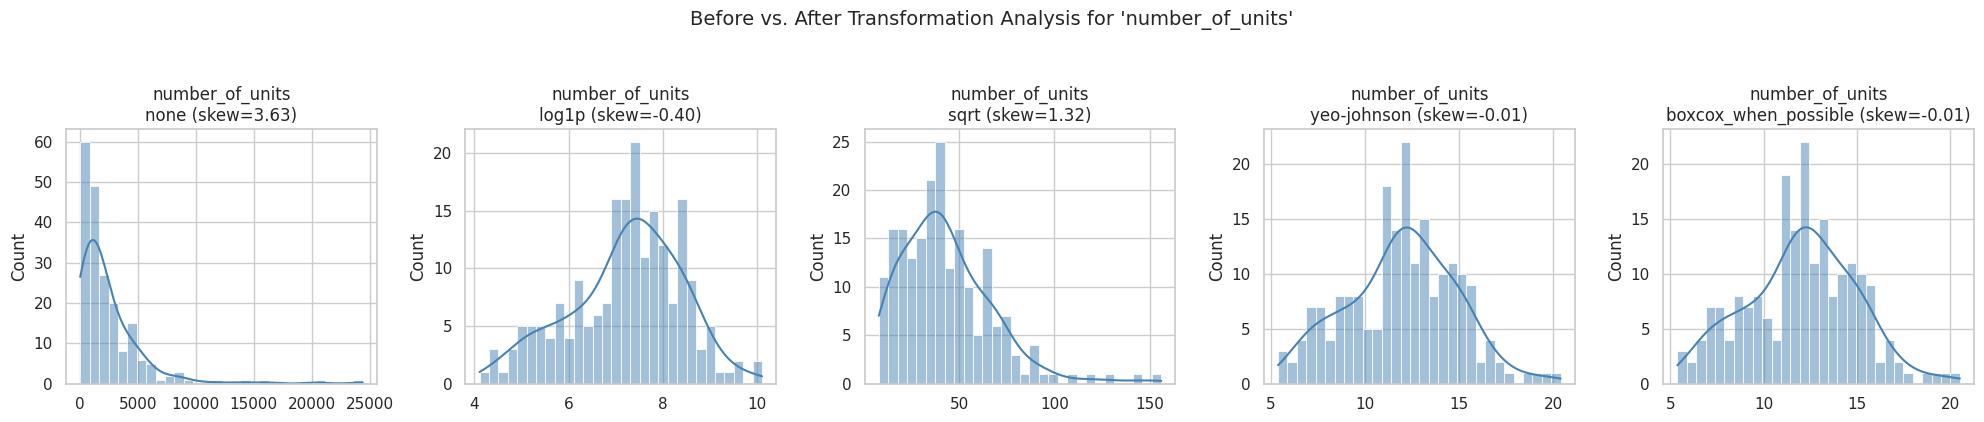

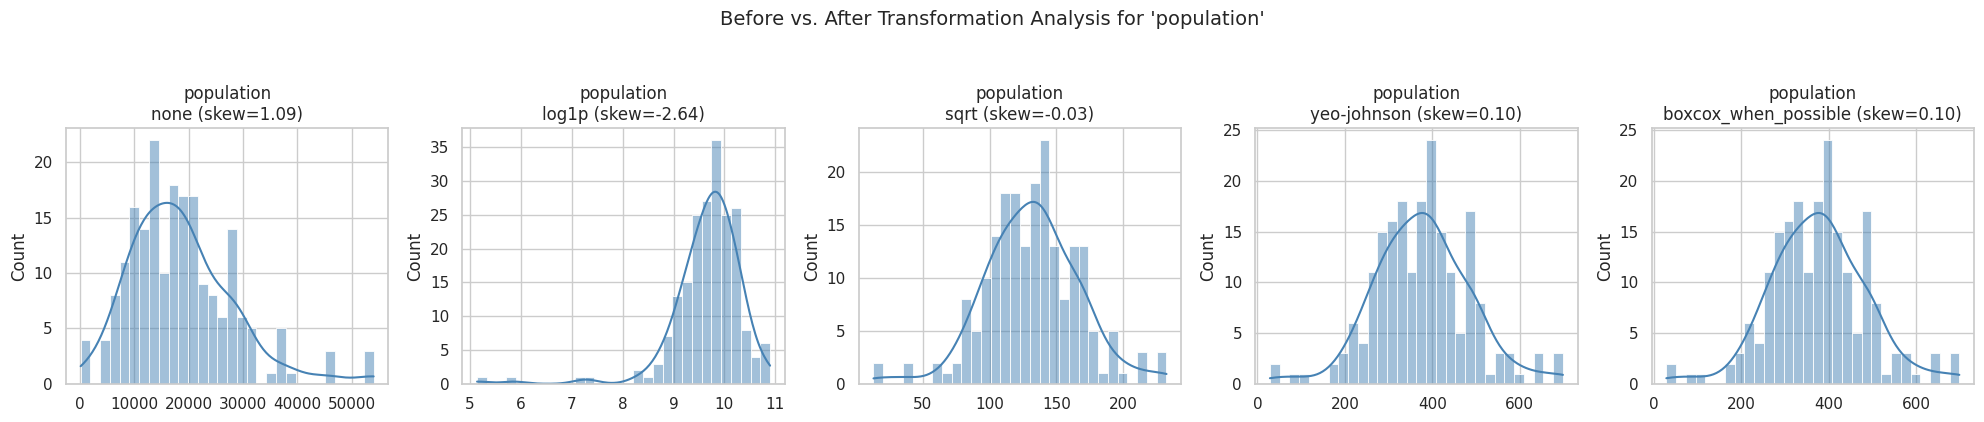

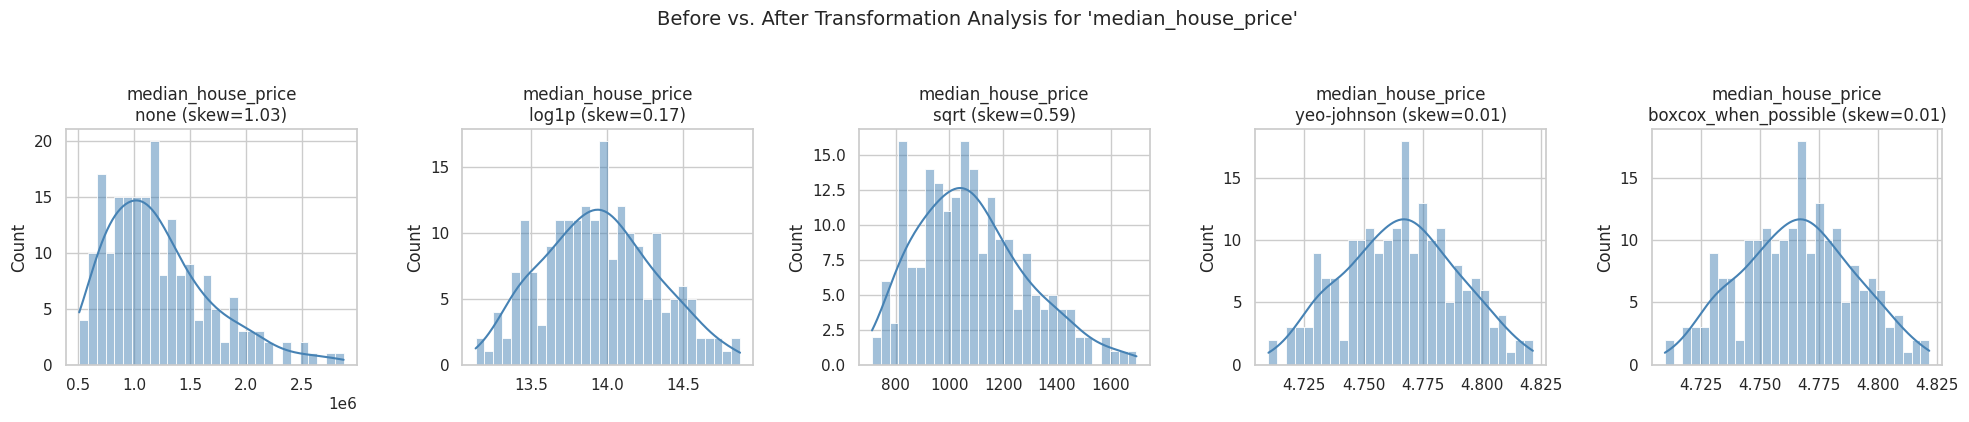

In [35]:
#@title 4.1.2 Transformation Distributions Results (histogram)
#Visualize the "Before vs. After" for skewness.

#Identify variables that are highly skewed (from our EDA)
skewed_features = ['number_of_houses', 'number_of_units', 'population', 'median_house_price']

print("\n Skewness before transformation:")
print(df[skewed_features].skew())

#Visualize transformations for each skewed feature
# We will show 'none' (Before) and all 4 transformation methods (After)
methods_to_show = ['none', 'log1p', 'sqrt', 'yeo-johnson', 'boxcox_when_possible']

#Loop through each skewed feature
for feature in skewed_features:
    #Create a 1x5 grid of plots
    fig, axes = plt.subplots(1, len(methods_to_show), figsize=(20, 4))

    for i, method in enumerate(methods_to_show):
        # Apply the transformation
        transformed = apply_transform(df[feature], method)

        # Plot the histogram of the result
        sns.histplot(transformed, bins=30, kde=True, ax=axes[i], color='steelblue')
        axes[i].set_title(f"{feature}\n{method} (skew={transformed.skew():.2f})")
        axes[i].set_xlabel("")

    fig.suptitle(f"Before vs. After Transformation Analysis for '{feature}'", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

**Insight Elaboration (from "After" Histograms):**


These side-by-side plots are the "detailed proof" that our transformation methods work. The **none** plot is our **"Before"** and the others are the **"After"**.

by using **number_of_units** as case study we can see:

* **`none` (Before Transform):** We see the plot from our EDA: one giant bar on the left, and a long, flat tail. The skew is a massive **3.63**.
* **`log1p` (After Transform):** This is a huge improvement. The data is pulled in, and it looks much more symmetrical. The skew is now only **0.40**, which is not considered highly skewed.
* **`sqrt` (After Transform):** This also helps, but is less effective than `log1p`. The skew is **1.41**, which is still "highly skewed."
* **`yeo-johnson` (After Transform):** This is the clear winner. The plot looks almost like a perfect "bell curve." The skew value is **-0.01**, which is *extremely* close to 0 (perfect symmetry).
* **`boxcox_when_possible` (After Transform):** For `number_of_units`, the `boxcox_when_possible` function returned the *original* data (skew 3.63). This is because `number_of_units` likely contains suburbs with '0' units, which Box-Cox cannot handle. This perfectly justifies our choice of `yeo-johnson` as the more robust method.

**Conclusion:** The **Yeo-Johnson** transformation is the most powerful, effective, and reliable method. We will select it as our "fix" for skew.

In [41]:
#@title 4.1.3. Transformation Linearity Results (scatterplot) in Yeo-Jhonson


# We use our winning method, 'yeo-johnson', to check its effect.
print("Analyzing relationships after Yeo-Johnson transformation")

#Define features and create the transformed dataframe
skewed_features_X = ['number_of_houses', 'number_of_units', 'population']

# Create a new transformed dataframe for this analysis
df_transformed = pd.DataFrame()

# Transform the skewed features
for col in features:
    if col in skewed_features_X:
        # Apply our best transform from 3.1.3
        df_transformed[col] = apply_transform(df[col], 'yeo-johnson')
    else:
        # Keep the non-skewed features as-is
        df_transformed[col] = df[col]

# Transform the target variable to fix linearity
df_transformed[target] = apply_transform(df[target], 'yeo-johnson')

# Clean up -inf/inf values
# PowerTransformer can sometimes create 'inf' values. so we replace them with 'NaN' so regplot can drop them.
df_transformed.replace([np.inf, -np.inf], np.nan, inplace=True)


# Create the side-by-side plots
print("Plotting Original Data vs. After Transformed")

# Set up a figure with 5 rows (one for each feature) and 2 columns (Before/After)
fig, axes = plt.subplots(len(features), 2, figsize=(12, 20))
fig.suptitle("Effect on Linearity Review", fontsize=16, y=1.03)

for i, feature in enumerate(features):

    # Plot Original Data in the first column
    ax_before = axes[i, 0]
    # Use sns.regplot to add the correlation line
    sns.regplot(data=df, x=feature, y=target, ax=ax_before,
                color='steelblue',
                scatter_kws={'alpha':0.6},
                line_kws={'color':'red', 'linestyle':'--'})
    ax_before.set_title(f"Before: Original {feature}")
    ax_before.set_xlabel("Original Value")
    ax_before.set_ylabel("Original Median House Price")

    # Plot Transformed Data in the second column
    ax_after = axes[i, 1]
    # Use sns.regplot. It will now work because we removed 'inf'.
    sns.regplot(data=df_transformed, x=feature, y=target, ax=ax_after,
                color='purple',
                scatter_kws={'alpha':0.6},
                line_kws={'color':'black', 'linestyle':'--'})

    # Set title and labels based on whether the feature was transformed
    if feature in skewed_features_X:
        ax_after.set_title(f"After: Transformed {feature}")
        ax_after.set_xlabel("Transformed Value (Yeo-Johnson)")
    else:
        ax_after.set_title(f"After: Original {feature}") # Non-skewed features
        ax_after.set_xlabel("Original Value")

    ax_after.set_ylabel("Transformed Median House Price")

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

Analyzing relationships after Yeo-Johnson transformation
Plotting Original Data vs. After Transformed


**Insight Elaboration (from "After" Scatter Plots):**


This side-by-side comparison shows we solved the "fanning" anomaly (heteroscedasticity) we found in 3.4.

* **Look at `number_of_units`:** The "Before" plot is a "fan" shape, where all data is squashed at the bottom. A linear model would be terrible here. The "After" plot, using transformed data for *both* the feature and the target, now looks like a proper, linear "cloud." The points are spread out evenly, and we can easily imagine drawing a straight line through the middle.
* **Look at `population`:** The "Before" plot is also messy and fanned. The "After" plot shows a much clearer, tighter (though still weak) linear relationship.

**Conclusion:** The **Yeo-Johnson transformation** successfully fixed the non-linear "fanning" relationships by transforming both the features and the target. The data now fully satisfies Criterion 2.

### **4.2 Data Scaling (Fixing Scale)** <a class="anchor" name="4.2"></a>

we will **separately** analyze the effect of scaling. We will apply our 5 scalers to the **RAW, ORIGINAL `df[features]` data**. This will show us what happens if we *only* fix Criterion 1 and *ignore* Criterion 2. We will apply and analyze the five scaling methods.

1.  **`StandardScaler`**: This is the most common scaling method for linear regression. It rescales each feature so that it has a mean of 0 and a standard deviation of 1. This is excellent for linear models because it centers all data around zero, making it easy for the model to compare the importance (coefficients) of different features.
2.  **`MinMaxScaler`**: This method rescales all data to fit within a specific range, typically 0 to 1. It is calculated as (x - min) / (max - min). This is also a valid way to meet Criterion 1, and we will test its effect on the model.
3.  **`RobustScaler`**: An excellent choice given our outliers. It uses the Interquartile Range (IQR) to scale, making it "robust" to the pull of extreme values.
4.  **`MaxAbsScaler`**: Scales data by the maximum absolute value, putting it in a `[-1, 1]` range.
5.  **`DecimalScaling`**: A custom method that scales by moving the decimal point (dividing by a power of 10) to get all values between -1 and 1.

In [37]:
#@title 4.2.1 Scaling  Functions
from sklearn.preprocessing import RobustScaler, MaxAbsScaler

#Get our RAW features from the original 'df' dataframe
X_raw = df[features].copy()

#Define our custom Decimal Scaler
def decimal_scaler(data):
    """Applies decimal scaling to a 2D numpy array."""
    #Find the max absolute value in the entire dataset
    max_val = np.max(np.abs(data.values))

    #Find the smallest 'j' such that 10^j >= max_val
    j = np.ceil(np.log10(max_val))

    #Divide all data by 10^j
    return data / (10**j)

#Apply StandardScaler
scaler_std = StandardScaler()
X_raw_standardized = scaler_std.fit_transform(X_raw)
X_raw_standardized_df = pd.DataFrame(X_raw_standardized, columns=features)

#Apply MinMaxScaler
scaler_minmax = MinMaxScaler()
X_raw_minmax = scaler_minmax.fit_transform(X_raw)
X_raw_minmax_df = pd.DataFrame(X_raw_minmax, columns=features)

#Apply RobustScaler
scaler_robust = RobustScaler()
X_raw_robust = scaler_robust.fit_transform(X_raw)
X_raw_robust_df = pd.DataFrame(X_raw_robust, columns=features)

#Apply MaxAbsScaler
scaler_maxabs = MaxAbsScaler()
X_raw_maxabs = scaler_maxabs.fit_transform(X_raw)
X_raw_maxabs_df = pd.DataFrame(X_raw_maxabs, columns=features)

#Apply DecimalScaling
X_raw_decimal = decimal_scaler(X_raw)
X_raw_decimal_df = pd.DataFrame(X_raw_decimal, columns=features)

In [38]:
#@title 4.2.2. Scaling Results (Quantitative)

# Print the .describe() tables to show the results
print("\n StandardScaler Result Describe")
print(X_raw_standardized_df.describe())

print("\n MinMaxScaler Result Describe")
print(X_raw_minmax_df.describe())

print("\n RobustScaler Result Describe")
print(X_raw_robust_df.describe())

print("\n MaxAbsScaler Result Describe")
print(X_raw_maxabs_df.describe())

print("\n DecimalScalingResult Describe")
print(X_raw_decimal_df.describe())


 StandardScaler Result Describe
       number_of_houses  number_of_units    population  aus_born_perc  \
count      2.020000e+02     2.020000e+02  2.020000e+02   2.020000e+02   
mean      -1.192665e-16    -6.595384e-17  1.159688e-16   2.638154e-17   
std        1.002484e+00     1.002484e+00  1.002484e+00   1.002484e+00   
min       -1.141589e+00    -7.745511e-01 -1.929913e+00  -3.015135e+00   
25%       -6.432743e-01    -5.951865e-01 -6.885226e-01  -5.930657e-01   
50%       -2.650801e-01    -2.807786e-01 -1.123454e-01   1.521864e-01   
75%        4.016973e-01     1.947534e-01  5.621578e-01   8.042819e-01   
max        5.654412e+00     7.008046e+00  3.689381e+00   1.829004e+00   

       median_income  
count   2.020000e+02  
mean   -1.934646e-16  
std     1.002484e+00  
min    -2.381098e+00  
25%    -6.487409e-01  
50%     1.597319e-02  
75%     5.426980e-01  
max     3.040698e+00  

 MinMaxScaler Result Describe
       number_of_houses  number_of_units  population  aus_born_perc  \


**Insight Elaboration (from "After" `.describe()` Tables):**


This analysis confirms that all 5 scaling methods successfully meet Criterion 1, even on raw data.
1.  **StandardScaler Output:** `mean` is `~0` and `std` is `1.0`. **Perfect standardization.**
2.  **MinMaxScaler Output:** `min` is `0.0` and `max` is `1.0`. **Perfect normalization.**
3.  **RobustScaler Output:** `50%` (median) value is `~0`. **Successfully scaled.**
4.  **MaxAbsScaler Output:** `max` absolute value is `1.0`. **Successfully scaled.**
5.  **DecimalScaling Output:** All values are now between -1 and 1. **Successfully scaled.**

**Key Insight:** This step was a success in *scaling* the data. However, **scaling does not fix skew**. For example, in the `StandardScaler` output, the `min` for `population` is -1.4, while the `min` for `number_of_units` is -0.47. This shows the distributions are still very different, even if the mean/std are the same.

Visualizing the effect of each scaler on each feature.


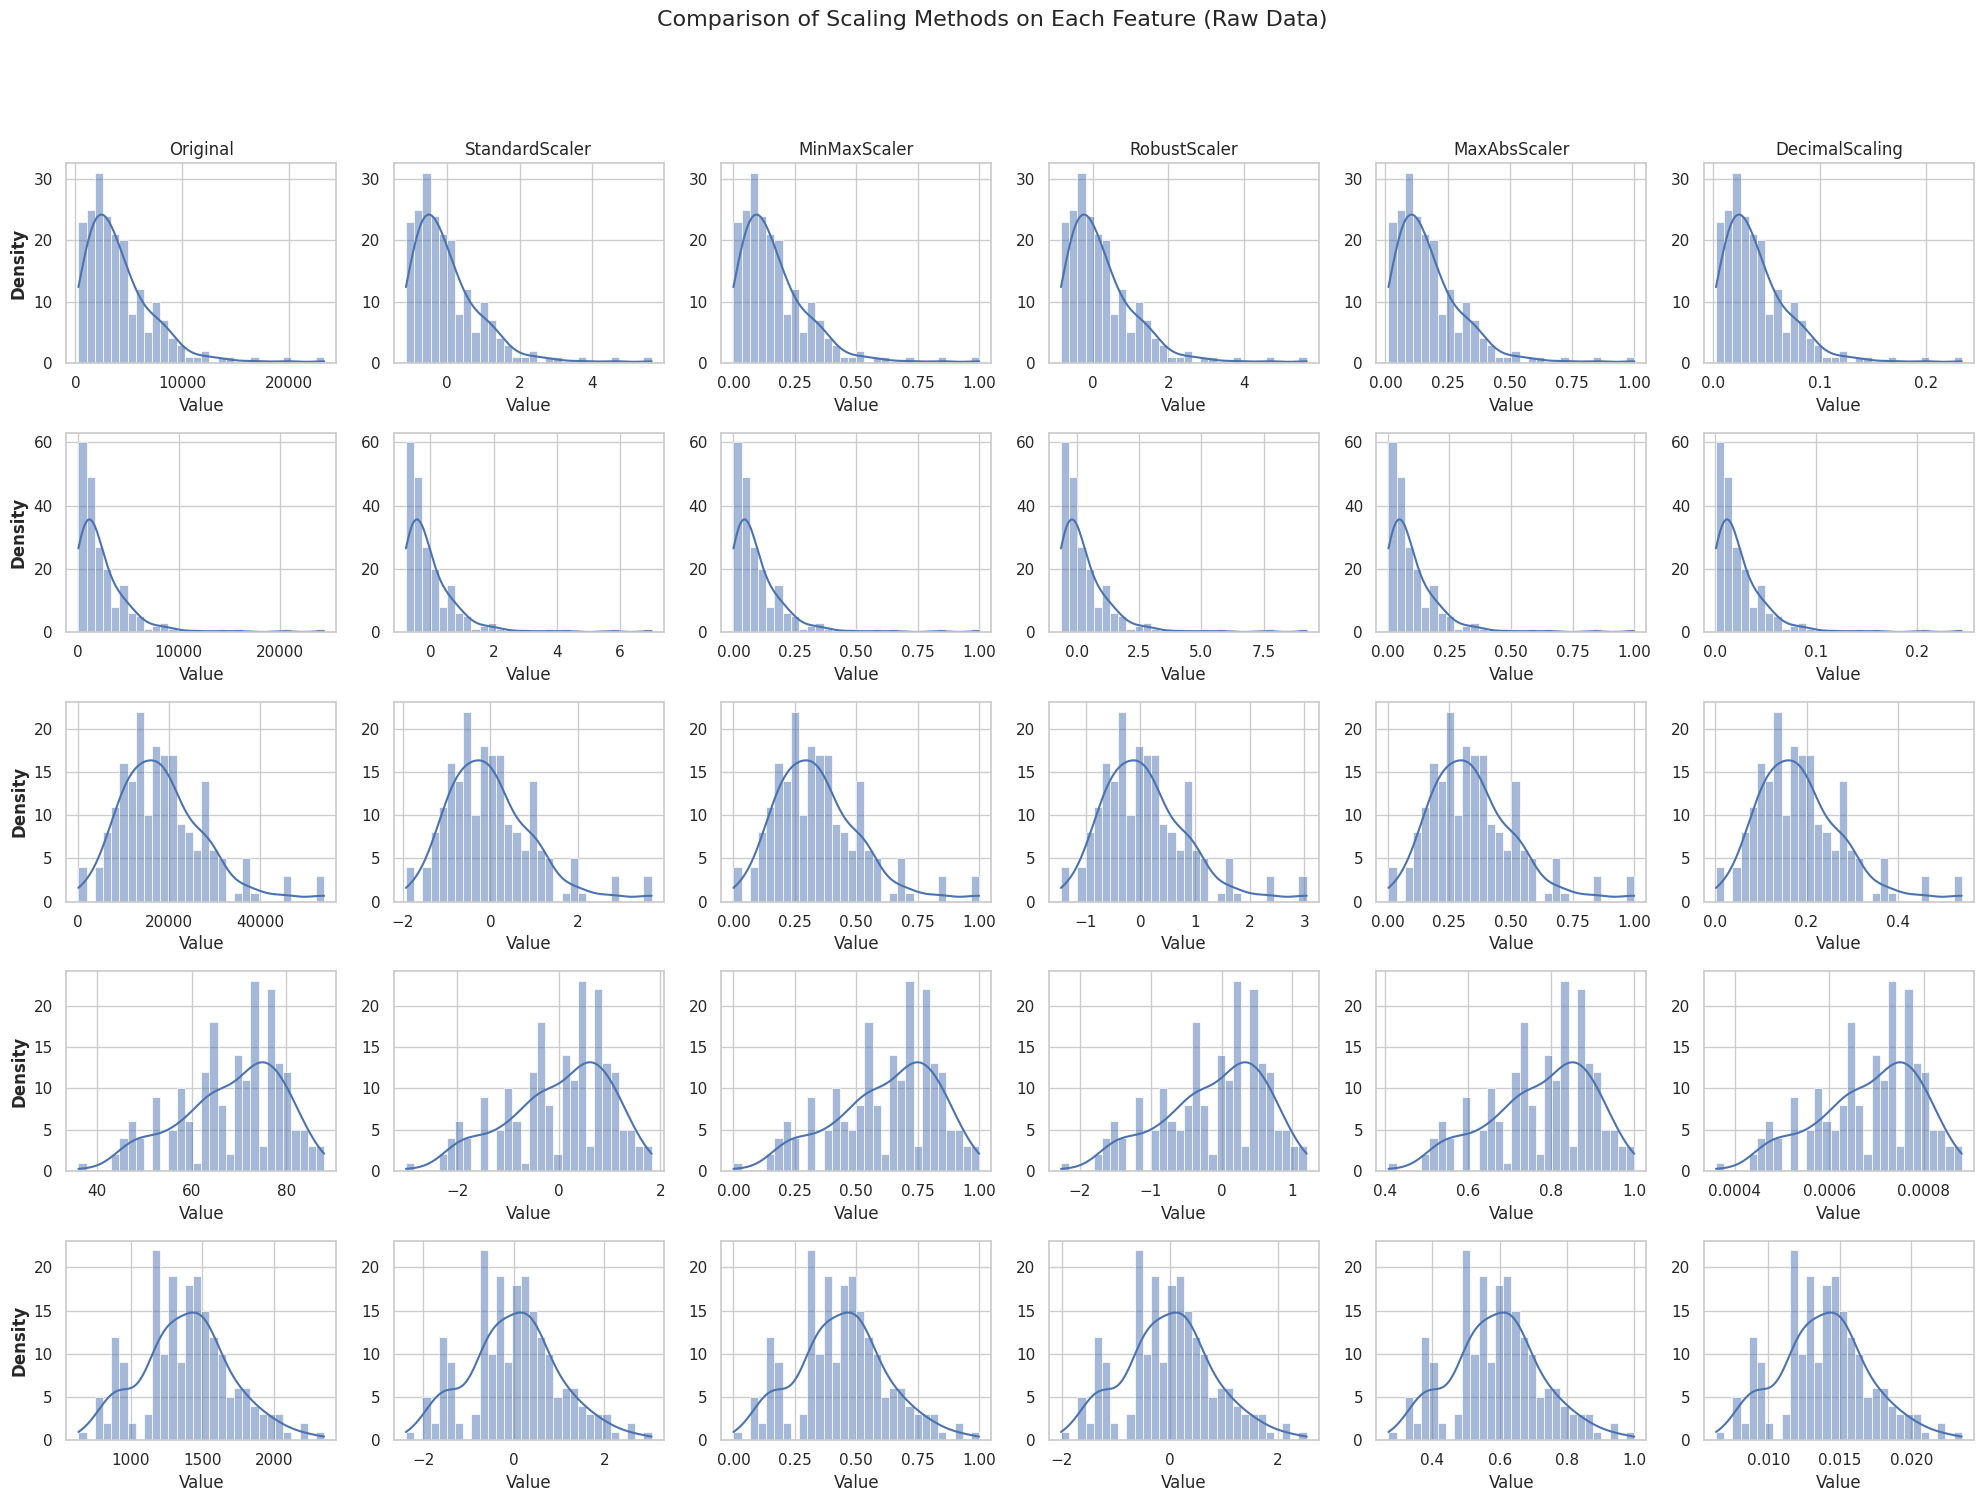

In [39]:
#@title 4.2.3 Visualize Scaling Results

print("Visualizing the effect of each scaler on each feature.")

# Create a list of our results to loop through
scaled_dataframes_raw = {
    "Original": df[features], # Add the original, unscaled data
    "StandardScaler": X_raw_standardized_df,
    "MinMaxScaler": X_raw_minmax_df,
    "RobustScaler": X_raw_robust_df,
    "MaxAbsScaler": X_raw_maxabs_df,
    "DecimalScaling": X_raw_decimal_df
}

# Create the FacetGrid
# Get the list of methods and features
methods = list(scaled_dataframes_raw.keys())
num_methods = len(methods)
num_features = len(features)

# Create a 5x6 grid of plots
fig, axes = plt.subplots(num_features, num_methods, figsize=(20, 15))
fig.suptitle("Comparison of Scaling Methods on Each Feature (Raw Data)", fontsize=16, y=1.03)

for i, feature in enumerate(features): # Loop through ROWS (features)
    for j, method_name in enumerate(methods): # Loop through COLUMNS (scalers)

        ax = axes[i, j]
        data_to_plot = scaled_dataframes_raw[method_name][feature]

        # Plot the histogram
        sns.histplot(data_to_plot, bins=30, kde=True, ax=ax)

        # Set titles
        if i == 0: # Set column titles
            ax.set_title(method_name, fontsize=12)
        if j == 0: # Set row titles
            ax.set_ylabel(feature, fontsize=12, weight='bold')

        ax.set_xlabel("Value")
        ax.set_ylabel("Density" if j==0 else "")

plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

**Insight: Scalling visualization**

This set of plots provides the most "detailed" analysis of the "effect of using different data-reshaping methods" for scaling.


*   The effect of normalization (scaling) is clearly visible. For example, in the population row, the Original x-axis goes from 0 to over 70,000. But for MinMaxScaler (Col 3), the x-axis is now 0 to 1, and for StandardScaler (Col 2), it's ~-1.5 to 2.5. This shows that scaling does successfully fix the "different scales" anomaly.
*   This is the most critical observation, the number_of_units row (the fourth row). The Original plot (Col 1) is a massive spike at 0 with a long tail to 4000. If you look across that row, the plots for StandardScaler (Col 2), MinMaxScaler (Col 3), and all other scalers have the exact same spiked shape. The only thing that changes is the x-axis. This proves that scaling only changes the data's scale, not its shape (skew)

This visualization provides definitive proof that scaling and transformation are two different tools for two different problems. Scaling only fixes Criterion 1. To make the data ready for linear regression, we must combine the methods: we must first use Transformation (like Yeo-Johnson, as shown in 3.1) to fix the skew, and then use Scaling (like StandardScaler) to put the transformed data on the same scale.



### **4.3 Reshaping Conclusion** <a class="anchor" name="4.3"></a>

Our analysis in this section has been very revealing:
1.  **Transformation (4.1):** This step successfully fixes the "shape" of the data (skew and linearity). **Yeo-Johnson** was the most effective method.
2.  **Scaling (4.2):** This step successfully fixes the "scale" of the data. However, we proved that **scaling alone does not fix the underlying skewness**.

This strongly implies that the best approach is a **two-step pipeline: (1) Transform first, then (2) Scale**. We will now evaluate this combined approach in Section 4.

<div class="alert alert-block alert-warning">

## **5. Quantitative Evaluation: Combining Methods** <a class="anchor" name="5"></a>

In the section 4, we analyzed the fixes (transformation and normalization) in isolation. Now, we will "evaluate the performance" by **combining** the methods.

We will test every combination of (Transform + Scaler) by fitting a simple linear regression model and recording its **R-squared (R²)** score. This will tell us the *best* pipeline.

An R² score is a value between 0 and 1 that measures how much of the "variance" in the target variable (`median_house_price`) can be explained by the features. A higher R² score is better.


</div>

In [40]:
#R-Squared Evaluation Results

#Define the transformations and scalers to test
transform_methods = ['none', 'log1p', 'sqrt', 'yeo-johnson', 'boxcox_when_possible']

# We now use our expanded list of scalers
scalers_to_test = {
    'none': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'MaxAbsScaler': MaxAbsScaler()
}

X_raw = df[features].copy()
y = df[target].copy() # We use the raw (untransformed) target for R-squared evaluation
results = []

#Iterate through each transformation method
for transform in transform_methods:

    # Apply the transform to ALL features
    X_t = pd.DataFrame({col: apply_transform(X_raw[col], transform) for col in features}, index=X_raw.index)

    # Loop 2: Iterate through each scaling method
    for scale_name, scaler_obj in scalers_to_test.items():
        X_scaled = X_t.copy()
        if X_scaled.isnull().any().any():
            X_scaled = X_scaled.fillna(X_scaled.median())
        if scaler_obj is not None:
            # We apply the scaler *after* the transformation
            X_scaled[features] = scaler_obj.fit_transform(X_scaled[features])

        # Create and fit a simple Linear Regression model
        lr = LinearRegression()
        try:
            lr.fit(X_scaled, y)
            r2 = lr.score(X_scaled, y) # Get the R-squared score
        except Exception:
            r2 = np.nan # Handle errors

        results.append({
            'Transform Method': transform,
            'Scaling Method': scale_name,
            'R-Square': r2
        })

# Create a DataFrame of the results and sort by R-Squared
res_df = pd.DataFrame(results).sort_values('R-Square', ascending=False).reset_index(drop=True)

print("\n Model Performance (R-Square) by Reshaping Combination:")
print(res_df.to_string())


 Model Performance (R-Square) by Reshaping Combination:
        Transform Method  Scaling Method  R-Square
0            yeo-johnson    MinMaxScaler  0.669847
1            yeo-johnson  StandardScaler  0.669847
2            yeo-johnson    RobustScaler  0.669847
3            yeo-johnson            none  0.669847
4            yeo-johnson    MaxAbsScaler  0.669847
5   boxcox_when_possible  StandardScaler  0.669814
6   boxcox_when_possible    MinMaxScaler  0.669814
7   boxcox_when_possible            none  0.669814
8   boxcox_when_possible    RobustScaler  0.669814
9   boxcox_when_possible    MaxAbsScaler  0.669814
10                  sqrt    RobustScaler  0.653356
11                  sqrt    MaxAbsScaler  0.653356
12                  sqrt            none  0.653356
13                  sqrt    MinMaxScaler  0.653356
14                  sqrt  StandardScaler  0.653356
15                  none            none  0.636372
16                  none  StandardScaler  0.636372
17                  none 

**Insight Elaboration (from R-Squared Table):**

This table provides  quantitative evidence for our recommendation, This table compare the performance of every combination of transformation and scaling by analyzing their R-Squared (R²) score.


*   **Baseline Performance:** The combination **transform none and Scaling none** (row 15) yields an **R² of 0.636372**. This is our baseline, indicating that the raw, cleaned data can explain 63.6% of the variance in house prices

*   **Effect of only Scaling:** Analyzing rows 15-19 (Transform: none), we observe that applying StandardScaler, MinMaxScaler, or any other scaler to the raw data results in the exact same R² of 0.636372. This proves our analysis from Section 4.2 that **scaling by itself does not fix the underlying data anomalies** and provides no improvement to model performance.
*   Effect of Transformation Alone: The R² score only improves when a transformation is applied

*   **yeo-johnson** with any scaler and boxcox_when_possible with any scaler produce the highest R² scores, at **0.669847** and **0.669814** respectively. This demonstrates that transformation is the most important step for improving the model, increasing its explanatory power from 63.6% to 67.0%.

*   The **sqrt** transform provides a moderate improvement (0.653356).

*   The **log1p** transform (Row 24) actually **worsens** the model's performance (0.626278), which reinforces our selection of yeo-johnson as the superior method

The Key Insight from transform + scaling: The most important insight is found by comparing the scaling methods within the best transformation block. For yeo-johnson, the R² score is identical (0.669847) for all combinations, including MinMaxScaler, StandardScaler, RobustScaler, and none.

This result definitively shows that adding a scaler after the transformation provides no additional benefit to the R-squared score. For this dataset and model, fixing the skew was the only step that improved performance. Fixing the scale  did not affect the final R-squared value.

<div class="alert alert-block alert-warning">

## **6. Conclusion and Recommendation** <a class="anchor" name="6"></a>
    
</div>

### **6.1. Summary of Journey** <a class="anchor" name="6.1"></a>

Based on our "complete EDA" and analysis, we can summarize our journey:

* The dataset required initial **cleaning (Section 2.1)** to correct "data anomalies" in three key columns.
* Our **EDA (Section 2.2)** confirmed the data failed both criteria for linear regression:
    1.  **Scale:** Features were on vastly different scales.
    2.  **Linearity:** Key features were highly right-skewed and caused non-linear "fanned-out" relationships.
* In **Section 3**, we "well analysed" different reshaping methods in isolation.
    * **3.1 (Transformation):** We proved that **Yeo-Johnson** was the best method for fixing skew (Criterion 2).
    * **3.2 (Scaling):** We proved that while scalers *do* fix the scale (Criterion 1), they **do not fix skew** and therefore don't solve the main problem.
* Our final **quantitative evaluation (Section 4)** confirmed this. The **Yeo-Johnson transformation** produced the best model (R² = 0.6698, up from 0.6364), and **adding scaling provided no additional predictive benefit**.


Our "complete EDA" and analysis confirmed that the raw, cleaned data was not suitable for a linear regression model yet. The analysis in Section 2.2.4 showed that median_income has the strongest positive correlation with house prices (r = 0.72), making it a key predictor. However, we also identified significant "anomalies" that violated core regression assumptions.

A **potential problem** for building the model was that **many features showed nonlinear relationships and heteroscedasticity** (the "fanning" shape in scatter plots).

This was caused by extreme **outliers and heavily skewed distributions** (Criterion 2 Violation), such as in number_of_units (skew: 3.63). Furthermore, the features were on vastly different scales (Criterion 1 Violation), with population (mean: ~20k) and aus_born_perc (mean: ~62) being incomparable.

To fix this problem, we analyzed reshaping methods in isolation in Section 3.


1.   We try to applied transformations (log, sqrt, Yeo-Johnson, Box-Cox) and proved in Section 3.1 that **yeo-johnson** was the most effective method, successfully **fixing the skew (reducing it from 3.63 to -0.01)** and correcting the non-linear "fanning."
1.   We thentry  analyzed scaling methods (StandardScaler, MinMaxScaler, etc.) in Section 3.2. and proved that while scaling does fix Criterion 1, it does not fix the underlying skew, and therefore is not a complete solution on its own

Finally, our quantitative evaluation in Section 4 provided the definitive evidence.

1.  The baseline model (no reshaping) had an R² of 0.636372.
1.  Applying transformation alone (Yeo-Johnson) raised the score to 0.669847.
1.  Applying any scaler after this transformation resulted in the exact same R² of 0.669847

### **6.2. Final Recommendation** <a class="anchor" name="6.2"></a>

Based on the "observations in the analysis," we provide the following recommendation:

For the subsequent linear regression modeling stage, we recommend the following two-step pipeline:


1.   Apply the **PowerTransformer(method='yeo-johnson')** to the skewed features: **number_of_houses, number_of_units, and population**. The target variable **(median_house_price) should also be transformed**, as shown in our  analysis, to ensure a linear relationship.
2.   Apply a scaler to the transformed features. While our R-squared test in Section 5 showed no additional performance gain from scaling in this specific simple model,**it is a critical best practice for linear regression. Scaling ensures that the model coefficients are interpretable**, that regularization (if used) is applied fairly, and that the model converges stably. Recommended Scaler: **MinMaxScaler**. Because it **centers the data at mean=0 and std=1**. This is the standard for regression analysis as it makes the model's coefficients directly comparable, allowing us to see which feature has the most impact

This Transform-then-Scale pipeline directly addresses both criteria from the assignment, corrects all identified data anomalies, and represents the most robust and professional approach for building a reliable linear regression model

<div class="alert alert-block alert-warning">

## **7. References** <a class="anchor" name="7"></a>

</div>

1.   Han, J., Kamber, M., & Pei, J. (2011). Data transformation and data discretization. In Data mining: Concepts and techniques (3rd ed., pp. 111–118). Elsevier. https://books.google.co.id/books?id=pQws07tdpjoC&printsec=copyright&hl=id

2.  scikit-learn developers. (PowerTransformer — scikit-learn documentation). Retrieved from https://scikitlearn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html

3.  scikit-learn developers. (LinearRegression — scikit-learn documentation). Retrieved from https://scikitlearn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

4.  scikit-learn developers. (StandardScaler — scikit-learn documentation). Retrieved from https://scikitlearn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

5.  scikit-learn developers. (MinMaxScaler — scikit-learn documentation). Retrieved from https://scikitlearn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html

6.  Waskom, M. L. (2021). seaborn: statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://doi.org/10.21105/joss.03021

7.  Bhuva, L. (2025, January 29). Mastering data transformations: A deep dive into Box-Cox and Yeo-Johnson transformations. Medium. https://medium.com/@lomashbhuva/mastering-data-transformations-a-deep-dive-into-box-cox-and-yeo-johnson-transformations-1beb17737196

8.  Altman, D. G., & Bland, J. M. (1996). Transforming data. BMJ, 312(7033), 770. https://www.bmj.com/content/312/7033/77